# Week 7 — Data Pipelines & Automation (ETL)
### AnalystLab Africa Internship — Batch C

**Objective:** Build a simple ETL pipeline that extracts real-time weather data from the OpenWeather API, transforms it into a clean structured format, and loads it into a CSV file for analysis.

**Cities analyzed:** Lagos, Cotonou, Paris

**Tools:** Python, Requests, Pandas, OpenWeather API


In [3]:
!pip install --user -r requirements.TXT

Accès refusé.


## 0. Setup

Make sure `config.py` contains your own OpenWeather API key before running this notebook.

In [5]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\Paracleto\Desktop\MTK\week7_weather_etl
['.ipynb_checkpoints', 'config_template-Copy1.py', 'config_template.py', 'data', 'etl_pipeline.py', 'README.md', 'requirements.txt', 'weather_etl_analysis.ipynb']


In [1]:
import requests
import pandas as pd
from datetime import datetime
import os

from config import OPENWEATHER_API_KEY, CITIES

BASE_URL = "https://api.openweathermap.org/data/2.5/weather"
print("Cities to analyze:", CITIES)

Cities to analyze: ['Lagos', 'Cotonou', 'Paris']


## Task 1: Extract
Connect to the OpenWeather API and retrieve current weather data for each city:
City Name, Temperature, Humidity, Weather Condition, Wind Speed, Date and Time.

In [2]:
def extract_weather_data(cities, api_key):
    raw_records = []
    for city in cities:
        params = {"q": city, "appid": api_key, "units": "metric"}
        response = requests.get(BASE_URL, params=params)
        if response.status_code == 200:
            raw_records.append(response.json())
            print(f"[OK] Data extracted for {city}")
        else:
            print(f"[ERROR] Failed for {city}: {response.status_code} - {response.text}")
    return raw_records

raw_data = extract_weather_data(CITIES, OPENWEATHER_API_KEY)
raw_data

[OK] Data extracted for Lagos
[OK] Data extracted for Cotonou
[OK] Data extracted for Paris


[{'coord': {'lon': 3.75, 'lat': 6.5833},
  'weather': [{'id': 803,
    'main': 'Clouds',
    'description': 'broken clouds',
    'icon': '04d'}],
  'base': 'stations',
  'main': {'temp': 30.16,
   'feels_like': 34,
   'temp_min': 30.16,
   'temp_max': 30.16,
   'pressure': 1014,
   'humidity': 64,
   'sea_level': 1014,
   'grnd_level': 1014},
  'visibility': 10000,
  'wind': {'speed': 3.6, 'deg': 226, 'gust': 3.44},
  'clouds': {'all': 81},
  'dt': 1787232247,
  'sys': {'country': 'NG', 'sunrise': 1787204360, 'sunset': 1787248674},
  'timezone': 3600,
  'id': 2332453,
  'name': 'Lagos',
  'cod': 200},
 {'coord': {'lon': 2.4183, 'lat': 6.3654},
  'weather': [{'id': 803,
    'main': 'Clouds',
    'description': 'broken clouds',
    'icon': '04d'}],
  'base': 'stations',
  'main': {'temp': 29.99,
   'feels_like': 36.01,
   'temp_min': 29.99,
   'temp_max': 29.99,
   'pressure': 1013,
   'humidity': 74,
   'sea_level': 1013,
   'grnd_level': 1012},
  'visibility': 10000,
  'wind': {'speed'

## Task 2: Transform
Clean and structure the raw JSON data into a Pandas DataFrame with renamed columns and correct data types.

In [3]:
def transform_weather_data(raw_records):
    cleaned_rows = []
    for record in raw_records:
        cleaned_rows.append({
            "city": record["name"],
            "temperature_celsius": record["main"]["temp"],
            "humidity_percent": record["main"]["humidity"],
            "weather_condition": record["weather"][0]["description"].title(),
            "wind_speed_ms": record["wind"]["speed"],
            "date_time": datetime.utcfromtimestamp(record["dt"]).strftime("%Y-%m-%d %H:%M:%S")
        })
    df = pd.DataFrame(cleaned_rows)
    df["temperature_celsius"] = df["temperature_celsius"].astype(float)
    df["humidity_percent"] = df["humidity_percent"].astype(int)
    df["wind_speed_ms"] = df["wind_speed_ms"].astype(float)
    df["date_time"] = pd.to_datetime(df["date_time"])
    return df

df_clean = transform_weather_data(raw_data)
df_clean

C:\Users\Paracleto\AppData\Local\Temp\ipykernel_13536\2235090081.py:10: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  "date_time": datetime.utcfromtimestamp(record["dt"]).strftime("%Y-%m-%d %H:%M:%S")


,city,temperature_celsius,humidity_percent,weather_condition,wind_speed_ms,date_time
0,Lagos,30.16,64,Broken Clouds,3.60,2026-08-20 13:24:07
1,Cotonou,29.99,74,Broken Clouds,4.63,2026-08-20 13:31:13
2,Paris,24.52,46,Overcast Clouds,7.20,2026-08-20 13:30:45


In [4]:
df_clean.info()
df_clean.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   city                 3 non-null      object        
 1   temperature_celsius  3 non-null      float64       
 2   humidity_percent     3 non-null      int64         
 3   weather_condition    3 non-null      object        
 4   wind_speed_ms        3 non-null      float64       
 5   date_time            3 non-null      datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1), object(2)
memory usage: 276.0+ bytes


,temperature_celsius,humidity_percent,wind_speed_ms,date_time
count,3.000000,3.000000,3.000000,3
mean,28.223333,61.333333,5.143333,2026-08-20 13:28:41.666666496
min,24.520000,46.000000,3.600000,2026-08-20 13:24:07
25%,27.255000,55.000000,4.115000,2026-08-20 13:27:26
50%,29.990000,64.000000,4.630000,2026-08-20 13:30:45
75%,30.075000,69.000000,5.915000,2026-08-20 13:30:59
max,30.160000,74.000000,7.200000,2026-08-20 13:31:13
std,3.208307,14.189198,1.854086,NaN


## Task 3: Load
Save the cleaned dataset to a timestamped CSV file.

In [5]:
os.makedirs("data", exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filepath = f"data/weather_data_{timestamp}.csv"
df_clean.to_csv(filepath, index=False)
print(f"Data saved to {filepath}")

Data saved to data/weather_data_20260820_153145.csv


## Task 4: Basic Analysis
- Compare temperatures across cities
- Identify the city with the highest humidity
- Compare weather conditions

In [6]:
hottest = df_clean.loc[df_clean["temperature_celsius"].idxmax()]
coldest = df_clean.loc[df_clean["temperature_celsius"].idxmin()]
most_humid = df_clean.loc[df_clean["humidity_percent"].idxmax()]

print(f"Hottest city:    {hottest['city']} ({hottest['temperature_celsius']}°C)")
print(f"Coldest city:    {coldest['city']} ({coldest['temperature_celsius']}°C)")
print(f"Most humid city: {most_humid['city']} ({most_humid['humidity_percent']}%)")

df_clean[["city", "weather_condition"]]

Hottest city:    Lagos (30.16°C)
Coldest city:    Paris (24.52°C)
Most humid city: Cotonou (74%)


,city,weather_condition
0,Lagos,Broken Clouds
1,Cotonou,Broken Clouds
2,Paris,Overcast Clouds


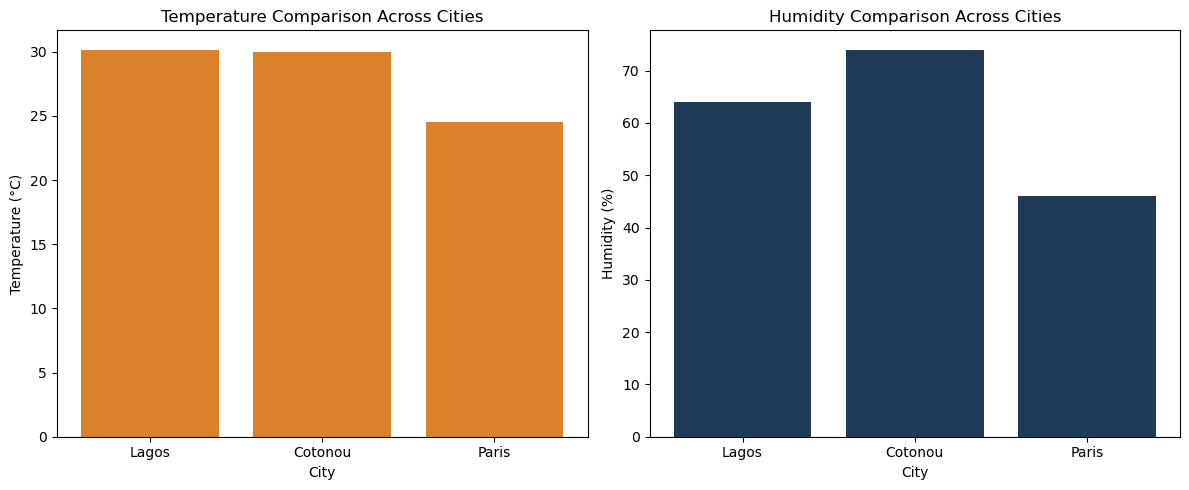

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(df_clean["city"], df_clean["temperature_celsius"], color="#d9822b")
axes[0].set_title("Temperature Comparison Across Cities")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_xlabel("City")

axes[1].bar(df_clean["city"], df_clean["humidity_percent"], color="#1f3b57")
axes[1].set_title("Humidity Comparison Across Cities")
axes[1].set_ylabel("Humidity (%)")
axes[1].set_xlabel("City")

plt.tight_layout()
plt.show()

## Key Findings


The ETL pipeline successfully extracted, transformed, and loaded real-time weather data 
for three cities on 20 August 2026. Lagos was the hottest city at 30.16°C, closely 
followed by Cotonou at 29.99°C, while Paris was noticeably cooler at 24.52°C — a gap of 
nearly 6°C between the West African cities and the European city. Cotonou recorded the 
highest humidity (74%), consistent with its coastal, tropical climate, compared to 
64% in Lagos and 46% in Paris. Weather conditions were similar in Lagos and Cotonou 
(broken clouds), while Paris showed overcast skies. These results confirm the expected 
climatic contrast between tropical West African cities and a temperate European city.

## Conclusion

This notebook demonstrates a complete ETL pipeline: extracting live weather data from a public REST API, transforming it into a structured, analysis-ready format with Pandas, and loading it into a CSV file for future use.